In [1]:
!pip install -q pyspark
from google.colab import drive
drive.mount('/content/drive')

from pyspark.sql import SparkSession
spark = (SparkSession.builder
         .appName("YelpSentiment")
         .config("spark.driver.memory", "10g")
         .getOrCreate())

df       = spark.read.parquet("/content/drive/MyDrive/yelp_project/reviews_clean.parquet")
business = spark.read.parquet("/content/drive/MyDrive/yelp_project/business.parquet")

# while developing: work on a 5% sample, then run the final version on all data
sample = df.sample(fraction=0.05, seed=42)

Mounted at /content/drive


In [2]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

from pyspark.sql.functions import (
    col, length, size, split, avg, expr
)

# Create a folder for saving charts
os.makedirs("figures", exist_ok=True)

# Set chart style
sns.set_theme(style="whitegrid")



# Exploratory Data Analysis (EDA)

This section explores the Yelp reviews dataset to understand its distribution, review lengths, and changes in review activity over time.

The analysis includes star and sentiment distribution, review length comparison, and yearly review trends.



### Task 1 — Star and Label Distribution

This task examines the number of reviews for each star rating and compares the total number of positive and negative reviews.

Positive reviews have 4–5 stars, while negative reviews have 1–2 stars. Three-star reviews were removed during Phase 1.


In [3]:

# Count reviews for each star rating
stars_pd = (df.groupBy("stars")
              .count()
              .orderBy("stars")
              .toPandas())

# Count positive and negative reviews
label_pd = (df.groupBy("label")
              .count()
              .orderBy("label")
              .toPandas())

# Replace numerical labels with names
label_pd["label"] = label_pd["label"].map({
    0: "Negative",
    1: "Positive"
})

print("Reviews per star rating:")
print(stars_pd)

print("\nPositive vs Negative reviews:")
print(label_pd)


Reviews per star rating:
   stars    count
0    1.0  1069507
1    2.0   544228
2    4.0  1452876
3    5.0  3231568

Positive vs Negative reviews:
      label    count
0  Negative  1613735
1  Positive  4684444


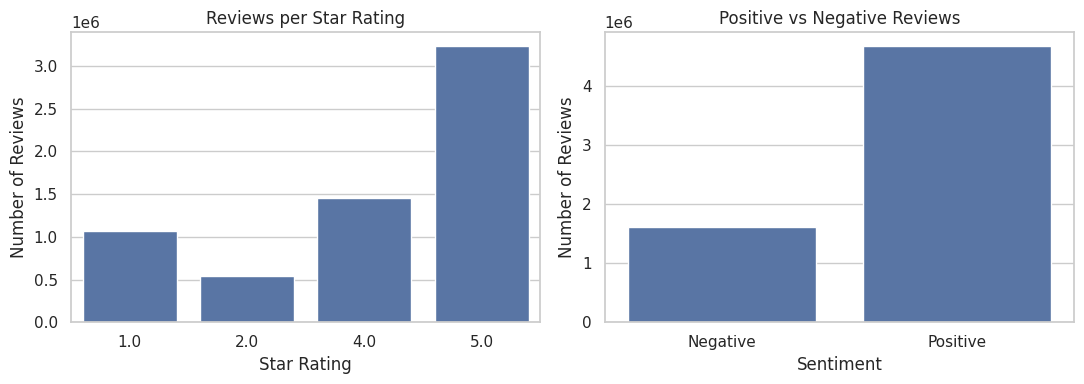

In [4]:

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Reviews per star rating
sns.barplot(
    data=stars_pd,
    x="stars",
    y="count",
    ax=ax[0]
)

ax[0].set_title("Reviews per Star Rating")
ax[0].set_xlabel("Star Rating")
ax[0].set_ylabel("Number of Reviews")

# Positive vs Negative reviews
sns.barplot(
    data=label_pd,
    x="label",
    y="count",
    ax=ax[1]
)

ax[1].set_title("Positive vs Negative Reviews")
ax[1].set_xlabel("Sentiment")
ax[1].set_ylabel("Number of Reviews")

plt.tight_layout()

plt.savefig("figures/01_label_distribution.png", dpi=300)

plt.show()



**Interpretation:**

The dataset contains significantly more positive reviews than negative reviews. Positive reviews represent approximately 74.4% of the dataset, while negative reviews represent 25.6%.

This shows that the dataset is imbalanced, with almost three positive reviews for every negative review. Therefore, accuracy alone may not be enough to evaluate the models in Phase 3. Metrics such as Precision, Recall, and F1-score will also be important.



### Task 2 — Review Length

This task compares the length of positive and negative reviews by calculating the average, median, and 95th percentile of the number of words.

A histogram will also be created to visualize the differences in review length between the two sentiment classes.


In [5]:

# Calculate the number of characters and words in each review
df_len = (df.withColumn("n_chars", length("text"))
            .withColumn("n_words", size(split(col("text"), r"\s+"))))

# Calculate average, median, and 95th percentile
length_stats = (df_len.groupBy("label")
    .agg(
        avg("n_words").alias("avg_words"),
        expr("percentile_approx(n_words, 0.5)").alias("median_words"),
        expr("percentile_approx(n_words, 0.95)").alias("p95_words")
    )
    .orderBy("label")
)

print("Review length statistics:")
length_stats.show()


Review length statistics:
+-----+-----------------+------------+---------+
|label|        avg_words|median_words|p95_words|
+-----+-----------------+------------+---------+
|    0| 134.102872528637|          98|      368|
|    1|91.80663041334255|          66|      251|
+-----+-----------------+------------+---------+



In [6]:

# Select review length and sentiment
# Use 1% of the dataset for plotting
len_pd = (df_len.select("n_words", "label")
                .sample(fraction=0.01, seed=42)
                .toPandas())

# Remove the longest 1% of reviews for a clearer chart
len_pd = len_pd[
    len_pd["n_words"] <= len_pd["n_words"].quantile(0.99)
]

# Convert numerical labels into readable names
len_pd["label"] = len_pd["label"].map({
    0: "Negative",
    1: "Positive"
})

print("Visualization sample size:", len(len_pd))
print(len_pd.head())


Visualization sample size: 62422
   n_words     label
0       88  Positive
1       41  Positive
2       79  Positive
3       84  Negative
4       51  Positive


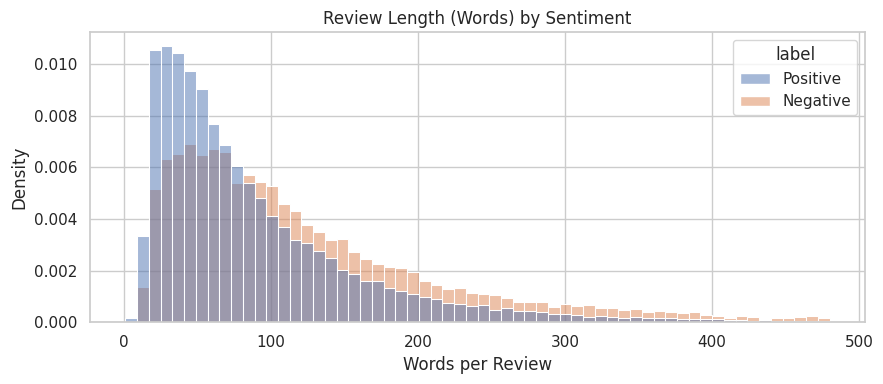

In [7]:

plt.figure(figsize=(9, 4))

sns.histplot(
    data=len_pd,
    x="n_words",
    hue="label",
    bins=60,
    stat="density",
    common_norm=False
)

plt.title("Review Length (Words) by Sentiment")
plt.xlabel("Words per Review")
plt.ylabel("Density")

plt.tight_layout()

plt.savefig("figures/02_review_length.png", dpi=300)

plt.show()



**Interpretation:**

Negative reviews are noticeably longer than positive reviews across all summary metrics:
- **Negative (0):** Average of **134.1 words** (median **98 words**, 95th percentile **368 words**).
- **Positive (1):** Average of **91.8 words** (median **66 words**, 95th percentile **251 words**).

This confirms that dissatisfied customers tend to write longer, more detailed descriptions when complaining, whereas satisfied customers often leave shorter, more concise positive feedback.



### Task 3 — Reviews and Sentiment Over Time

This task examines the number of Yelp reviews submitted each year and calculates the percentage of positive reviews over time.

The analysis will help identify changes in review activity and sentiment trends, including the drop in reviews during 2020.


In [8]:

# Group reviews by year
year_pd = (df.groupBy("year")
    .agg(
        expr("count(*)").alias("reviews"),
        avg("label").alias("positive_share")
    )
    .orderBy("year")
    .toPandas()
)

# Convert positive share into percentage
year_pd["positive_percentage"] = year_pd["positive_share"] * 100

print("Yearly review statistics:")
print(year_pd)


Yearly review statistics:
    year  reviews  positive_share  positive_percentage
0   2005      683        0.877013            87.701318
1   2006     3201        0.890347            89.034677
2   2007    12458        0.851100            85.109969
3   2008    39220        0.838424            83.842427
4   2009    61614        0.795160            79.516019
5   2010   115549        0.793758            79.375849
6   2011   194809        0.780200            78.020009
7   2012   245187        0.762051            76.205101
8   2013   332536        0.755190            75.519042
9   2014   461656        0.753516            75.351560
10  2015   616159        0.748635            74.863469
11  2016   686637        0.746623            74.662303
12  2017   744886        0.746120            74.611954
13  2018   829238        0.741390            74.139029
14  2019   832821        0.733476            73.347574
15  2020   517544        0.728717            72.871679
16  2021   574499        0.705932      

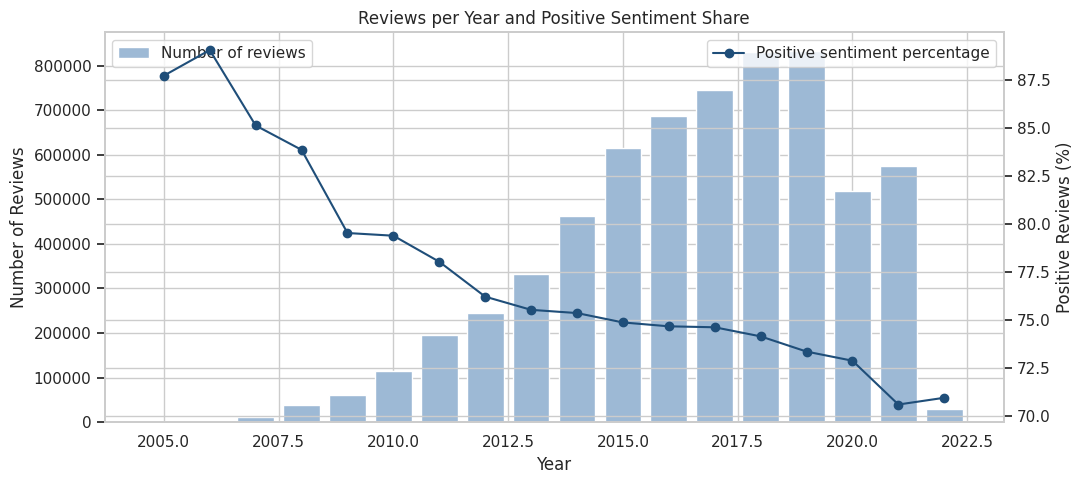

In [9]:

fig, ax1 = plt.subplots(figsize=(11, 5))

# Bar chart for the number of reviews
ax1.bar(
    year_pd["year"],
    year_pd["reviews"],
    color="#9DB9D5",
    label="Number of reviews"
)

ax1.set_xlabel("Year")
ax1.set_ylabel("Number of Reviews")
ax1.set_title("Reviews per Year and Positive Sentiment Share")

# Line chart for positive sentiment percentage
ax2 = ax1.twinx()

ax2.plot(
    year_pd["year"],
    year_pd["positive_percentage"],
    color="#1F4E79",
    marker="o",
    label="Positive sentiment percentage"
)

ax2.set_ylabel("Positive Reviews (%)")

# Add legends
ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.tight_layout()

plt.savefig("figures/03_reviews_per_year.png", dpi=300)

plt.show()



**Interpretation:**

The chart shows how Yelp review activity changes over time, together with the percentage of positive reviews each year.

The number of reviews increases over the years until 2019, followed by a noticeable drop in 2020, which may be related to the COVID-19 pandemic. Review activity recovers in 2021.

The 2022 data is incomplete, so it should not be directly compared with full years. The positive sentiment percentage also helps show whether customer opinions changed over time.


## Text Preprocessing Dependency for Task 4 (Guideline B.5)

This section defines and fits the Spark ML text preprocessing pipeline required by Task 4. It produces the `filtered` token column for sentiment word-frequency and distinctive-word analysis, as well as `bigrams` (`NGram(n=2)`) for negation phrase verification (e.g., `not good`). It preserves Tasks 1–3 unchanged and does not implement or modify Task 5.

### Pipeline Stages
1. **Lowercase normalization & null safety:** `lower(coalesce(text, ''))`.
2. **Apostrophe normalization & URL removal:** normalize curly/typographic apostrophes (`’`, `‘`, `ʼ`, `′`) to ASCII `'`, and strip `http://`, `https://`, and `www.` URLs.
3. **Contraction normalization:** expand negation and common English contractions (`didn't` → `did not`, `doesn't` → `does not`, `don't` → `do not`, `can't` → `can not`, `won't` → `will not`, `wasn't` → `was not`, `weren't` → `were not`, `isn't` → `is not`, `aren't` → `are not`, `I've` → `i have`, `they're` → `they are`, etc.) for both straight and curly apostrophes.
4. **Non-alphabetic removal & whitespace normalization:** replace non-alphabetic characters with spaces and collapse repeated whitespace to a single space.
5. **Tokenization:** `RegexTokenizer(pattern=r"\s+", minTokenLength=2)`.
6. **Stopword removal:** `StopWordsRemover` removing standard English stopwords while preserving `not`, `no`, `nor`, `never`, `very`, `too`, `but`, `against`, `only`, `most`, `more`, `few`, `off`, `over`, `again`.
7. **Bigrams:** `NGram(n=2)` over the `filtered` column.


In [10]:
from pyspark.sql.functions import col, explode, isnan, lit, log, sum as fsum, when
from pyspark.ml import Pipeline
from pyspark.ml.feature import SQLTransformer, RegexTokenizer, StopWordsRemover, NGram

# ==============================================================================
# Stage 1: Spark-native SQLTransformer for B.5 text cleaning (zero Python UDFs)
# ==============================================================================
_CLEANING_RULES = [
    # Normalize curly/typographic apostrophes to ASCII straight apostrophe (chr(39))
    (r"[\\u2018\\u2019\\u02bc\\u2032]", "chr(39)"),
    # Remove URLs (http://, https://, www.) across all whitespace boundaries
    (r"https?://\\S+|www\\.\\S+", "' '"),
    # Irregular negation contractions (applied before general n't rule)
    (r"\\bwon\\x27t\\b", "'will not'"),
    (r"\\bcan\\x27t\\b", "'can not'"),
    (r"\\bshan\\x27t\\b", "'shall not'"),
    (r"\\bain\\x27t\\b", "'am not'"),
    # Regular negation contractions (didn't, doesn't, don't, wasn't, weren't, isn't, aren't, ...)
    (r"(?<=[a-z])n\\x27t\\b", "' not'"),
    # Common non-negation contractions (I've, they're, we'll, I'm, ...)
    (r"(?<=[a-z])\\x27ve\\b", "' have'"),
    (r"(?<=[a-z])\\x27re\\b", "' are'"),
    (r"(?<=[a-z])\\x27ll\\b", "' will'"),
    (r"\\bi\\x27m\\b", "'i am'"),
    # Keep only lowercase English letters and whitespace
    (r"[^a-z\\s]", "' '"),
    # Normalize repeated whitespace (spaces, tabs, newlines) to a single space
    (r"\\s+", "' '"),
]

_clean_expr = "lower(coalesce(text, ''))"
for _pattern, _replacement in _CLEANING_RULES:
    _clean_expr = f"regexp_replace({_clean_expr}, '{_pattern}', {_replacement})"

cleaning_sql = f"SELECT *, trim({_clean_expr}) AS clean_text FROM __THIS__"
cleaner = SQLTransformer(statement=cleaning_sql)

# ==============================================================================
# Stage 2: RegexTokenizer (minTokenLength=2)
# ==============================================================================
tokenizer = RegexTokenizer(
    inputCol="clean_text",
    outputCol="tokens",
    pattern=r"\s+",
    minTokenLength=2
)

# ==============================================================================
# Stage 3: StopWordsRemover preserving required negation & sentiment modifiers
# ==============================================================================
keep = {
    "not", "no", "nor", "never", "very", "too", "but", "against",
    "only", "most", "more", "few", "off", "over", "again"
}
stop_words = [
    w for w in StopWordsRemover.loadDefaultStopWords("english")
    if w not in keep
]
remover = StopWordsRemover(
    inputCol="tokens",
    outputCol="filtered",
    stopWords=stop_words
)

# ==============================================================================
# Stage 4: Bigrams (NGram n=2)
# ==============================================================================
bigrams = NGram(n=2, inputCol="filtered", outputCol="bigrams")

# Assemble and fit the Spark-native preprocessing pipeline on the 5% sample (seed=42)
prep_pipeline = Pipeline(stages=[cleaner, tokenizer, remover, bigrams])
prep_model = prep_pipeline.fit(sample)
sample_tok = prep_model.transform(sample)

print("Preprocessing pipeline fitted and applied to 5% sample (sample_tok ready).")


Preprocessing pipeline fitted and applied to 5% sample (sample_tok ready).


### Task 4 – Preprocessing Diagnostics

This section isolates all preprocessing diagnostic checks so the notebook output stays concise while preserving the full row-level diagnostic results directly inside the notebook:

- **Code cell below:** Executes the 28-case diagnostic suite against `prep_pipeline` (covering straight/curly apostrophe contractions, negation preservation, all 15 preserved stopwords/modifiers, URL removal, tokenization with `minTokenLength=2`, bigrams, and noise/empty edge cases) plus a driver-safe null check on `sample_tok`, printing **only a short summary** in the cell output.
- **Markdown table below:** Records the complete row-by-row diagnostic results (`text`, `clean_text`, and `filtered`) in a readable table inside the notebook.


In [11]:
# ==============================================================================
# Task 4 – Preprocessing Diagnostics (Short Summary Output Only)
# ==============================================================================
_diagnostic_cases = [
    # Straight apostrophe contractions
    ("The waiter didn't smile.", "the waiter did not smile"),
    ("He doesn't smile.", "he does not smile"),
    ("I don't like it.", "i do not like it"),
    ("I can't recommend this restaurant.", "i can not recommend this restaurant"),
    ("I won't return.", "i will not return"),
    ("The service wasn't helpful.", "the service was not helpful"),
    ("They weren't polite.", "they were not polite"),
    ("This isn't fresh.", "this is not fresh"),
    ("They aren't friendly.", "they are not friendly"),
    ("I've been here twice.", "i have been here twice"),
    ("They're always polite.", "they are always polite"),
    # Curly apostrophe contractions
    ("The waiter didn\u2019t smile.", "the waiter did not smile"),
    ("He doesn\u2019t care.", "he does not care"),
    ("I don\u2019t agree.", "i do not agree"),
    ("I can\u2019t recommend this.", "i can not recommend this"),
    ("I won\u2019t come back.", "i will not come back"),
    ("The service wasn\u2019t helpful.", "the service was not helpful"),
    ("They weren\u2019t helpful.", "they were not helpful"),
    ("It isn\u2019t worth it.", "it is not worth it"),
    ("They aren\u2019t open.", "they are not open"),
    ("I\u2019ve ordered before.", "i have ordered before"),
    ("They\u2019re super fast.", "they are super fast"),
    # Negation, modifiers, URLs, and edge cases
    ("The food is not good.", "the food is not good"),
    ("I never want to visit again.", "i never want to visit again"),
    ("The food is very good.", "the food is very good"),
    ("Visit https://example.com/deal and www.yelp.com/biz/123 now!", "visit and now"),
    ("No, nor too few, but only more against off over most again!", "no nor too few but only more against off over most again"),
    ("   !!! 12345 ???   ", ""),
]

_diag_df = spark.createDataFrame(
    [(idx, txt) for idx, (txt, _) in enumerate(_diagnostic_cases)],
    ["id", "text"]
)
_diag_model = prep_pipeline.fit(_diag_df)
# Safe collect: fixed 28-row synthetic diagnostic DataFrame only (never project data)
_diag_out = {
    row["id"]: row
    for row in _diag_model.transform(_diag_df)
    .select("id", "text", "clean_text", "tokens", "filtered", "bigrams")
    .collect()
}

# 1. Exact clean_text verification across all 28 diagnostic cases
for idx, (raw_txt, expected_clean) in enumerate(_diagnostic_cases):
    actual_clean = _diag_out[idx]["clean_text"]
    assert actual_clean == expected_clean, (
        f"clean_text mismatch for {raw_txt!r}: expected {expected_clean!r}, got {actual_clean!r}"
    )

# 2. Negation, stopword preservation, tokenization (minTokenLength=2), and bigrams
assert _diag_out[0]["filtered"] == ["waiter", "not", "smile"]
assert "not smile" in _diag_out[0]["bigrams"]
assert "not" in _diag_out[3]["filtered"] and "recommend" in _diag_out[3]["filtered"]
assert "not" in _diag_out[4]["filtered"] and "return" in _diag_out[4]["filtered"]
assert "not" in _diag_out[16]["filtered"] and "not helpful" in _diag_out[16]["bigrams"]
assert "not" in _diag_out[22]["filtered"] and "not good" in _diag_out[22]["bigrams"]
assert {"never", "again"}.issubset(set(_diag_out[23]["filtered"]))
assert "very" in _diag_out[24]["filtered"] and "very good" in _diag_out[24]["bigrams"]
assert "example" not in _diag_out[25]["clean_text"] and "yelp" not in _diag_out[25]["clean_text"]

_all_preserved_seen = (
    set(_diag_out[22]["filtered"])
    | set(_diag_out[23]["filtered"])
    | set(_diag_out[24]["filtered"])
    | set(_diag_out[26]["filtered"])
)
assert keep.issubset(_all_preserved_seen), f"Missing preserved words: {keep - _all_preserved_seen}"

assert "i" not in _diag_out[9]["tokens"] and "have" in _diag_out[9]["tokens"]
assert "they" in _diag_out[10]["tokens"] and "are" in _diag_out[10]["tokens"]
assert _diag_out[27]["tokens"] == [] and _diag_out[27]["filtered"] == [] and _diag_out[27]["bigrams"] == []

# 3. Lightweight sample schema & null check (single aggregated row, no long output)
_sample_diag = sample_tok.agg(
    fsum(when(col("clean_text").isNull(), 1).otherwise(0)).alias("null_clean"),
    fsum(when(col("filtered").isNull(), 1).otherwise(0)).alias("null_filtered"),
).first()
assert _sample_diag["null_clean"] == 0 and _sample_diag["null_filtered"] == 0

# Print ONLY a short summary in the cell output
print("Task 4 – Preprocessing Diagnostics Summary")
print("-" * 42)
print(f"Synthetic cases passed : {len(_diagnostic_cases)} / {len(_diagnostic_cases)}")
print("Contractions & negs    : Straight & curly apostrophes + 15 preserved words verified")
print("Bigrams & URLs         : 'not good' / 'not smile' / 'very good' kept; URLs stripped")
print("Sample null check      : 0 null clean_text or filtered rows in sample_tok")
print("Full diagnostic table  : Recorded in the Markdown cell immediately below.")


Task 4 – Preprocessing Diagnostics Summary
------------------------------------------
Synthetic cases passed : 28 / 28
Contractions & negs    : Straight & curly apostrophes + 15 preserved words verified
Bigrams & URLs         : 'not good' / 'not smile' / 'very good' kept; URLs stripped
Sample null check      : 0 null clean_text or filtered rows in sample_tok
Full diagnostic table  : Recorded in the Markdown cell immediately below.


#### Diagnostic Results Table (`text`, `clean_text`, `filtered`)

The table below records the complete diagnostic outputs across all 28 test cases produced by the B.5 preprocessing pipeline:

| # | Category | Original Text (`text`) | Normalized Text (`clean_text`) | Filtered Tokens (`filtered`) | Status |
| :- | :--- | :--- | :--- | :--- | :---: |
| 1 | Straight apostrophe | `The waiter didn't smile.` | `the waiter did not smile` | `["waiter", "not", "smile"]` | PASS |
| 2 | Straight apostrophe | `He doesn't smile.` | `he does not smile` | `["not", "smile"]` | PASS |
| 3 | Straight apostrophe | `I don't like it.` | `i do not like it` | `["not", "like"]` | PASS |
| 4 | Straight apostrophe | `I can't recommend this restaurant.` | `i can not recommend this restaurant` | `["not", "recommend", "restaurant"]` | PASS |
| 5 | Straight apostrophe | `I won't return.` | `i will not return` | `["not", "return"]` | PASS |
| 6 | Straight apostrophe | `The service wasn't helpful.` | `the service was not helpful` | `["service", "not", "helpful"]` | PASS |
| 7 | Straight apostrophe | `They weren't polite.` | `they were not polite` | `["not", "polite"]` | PASS |
| 8 | Straight apostrophe | `This isn't fresh.` | `this is not fresh` | `["not", "fresh"]` | PASS |
| 9 | Straight apostrophe | `They aren't friendly.` | `they are not friendly` | `["not", "friendly"]` | PASS |
| 10 | Straight apostrophe | `I've been here twice.` | `i have been here twice` | `["twice"]` | PASS |
| 11 | Straight apostrophe | `They're always polite.` | `they are always polite` | `["always", "polite"]` | PASS |
| 12 | Curly apostrophe | `The waiter didn’t smile.` | `the waiter did not smile` | `["waiter", "not", "smile"]` | PASS |
| 13 | Curly apostrophe | `He doesn’t care.` | `he does not care` | `["not", "care"]` | PASS |
| 14 | Curly apostrophe | `I don’t agree.` | `i do not agree` | `["not", "agree"]` | PASS |
| 15 | Curly apostrophe | `I can’t recommend this.` | `i can not recommend this` | `["not", "recommend"]` | PASS |
| 16 | Curly apostrophe | `I won’t come back.` | `i will not come back` | `["not", "come", "back"]` | PASS |
| 17 | Curly apostrophe | `The service wasn’t helpful.` | `the service was not helpful` | `["service", "not", "helpful"]` | PASS |
| 18 | Curly apostrophe | `They weren’t helpful.` | `they were not helpful` | `["not", "helpful"]` | PASS |
| 19 | Curly apostrophe | `It isn’t worth it.` | `it is not worth it` | `["not", "worth"]` | PASS |
| 20 | Curly apostrophe | `They aren’t open.` | `they are not open` | `["not", "open"]` | PASS |
| 21 | Curly apostrophe | `I’ve ordered before.` | `i have ordered before` | `["ordered"]` | PASS |
| 22 | Curly apostrophe | `They’re super fast.` | `they are super fast` | `["super", "fast"]` | PASS |
| 23 | Negation & bigram | `The food is not good.` | `the food is not good` | `["food", "not", "good"]` | PASS |
| 24 | Negation & modifier | `I never want to visit again.` | `i never want to visit again` | `["never", "want", "visit", "again"]` | PASS |
| 25 | Modifier & bigram | `The food is very good.` | `the food is very good` | `["food", "very", "good"]` | PASS |
| 26 | URL removal | `Visit https://example.com/deal and www.yelp.com/biz/123 now!` | `visit and now` | `["visit"]` | PASS |
| 27 | Preserved words | `No, nor too few, but only more against off over most again!` | `no nor too few but only more against off over most again` | `["no", "nor", "too", "few", "but", "only", "more", "against", "off", "over", "most", "again"]` | PASS |
| 28 | Noise / empty edge case | `   !!! 12345 ???   ` | `""` *(empty)* | `[]` | PASS |


### Task 4 — Most Frequent Words per Sentiment

This task computes the most frequent words in positive (`label = 1`) and negative (`label = 0`) Yelp reviews using the `filtered` token array produced by the B.5 preprocessing pipeline on the 5% sample (`seed=42`).

Because high-frequency domain words (such as `food`, `place`, and `service`) occur frequently in both classes, we also compute **Log-Ratio** scores to identify the most statistically distinctive words for each sentiment.


In [12]:
# 1. Explode filtered tokens and count occurrences per (label, word) in Spark
word_counts = (
    sample_tok
    .select("label", explode("filtered").alias("word"))
    .groupBy("label", "word")
    .count()
    .cache()
)

# 2. Top 20 most frequent words per sentiment (sorted descending by count)
top20_pos = (
    word_counts
    .filter(col("label") == 1)
    .orderBy(col("count").desc(), col("word").asc())
)
top20_neg = (
    word_counts
    .filter(col("label") == 0)
    .orderBy(col("count").desc(), col("word").asc())
)

print("--- Top 20 words: Positive (label = 1) ---")
top20_pos.show(20, truncate=False)

print("--- Top 20 words: Negative (label = 0) ---")
top20_neg.show(20, truncate=False)


--- Top 20 words: Positive (label = 1) ---
+-----+---------+------+
|label|word     |count |
+-----+---------+------+
|1    |not      |208247|
|1    |but      |150360|
|1    |great    |129775|
|1    |food     |111526|
|1    |good     |110488|
|1    |place    |105694|
|1    |very     |99752 |
|1    |service  |68386 |
|1    |time     |66382 |
|1    |like     |60222 |
|1    |one      |60030 |
|1    |get      |58526 |
|1    |back     |58258 |
|1    |go       |55347 |
|1    |also     |53013 |
|1    |really   |52755 |
|1    |best     |51261 |
|1    |delicious|45884 |
|1    |love     |43590 |
|1    |friendly |43496 |
+-----+---------+------+
only showing top 20 rows
--- Top 20 words: Negative (label = 0) ---
+-----+-------+------+
|label|word   |count |
+-----+-------+------+
|0    |not    |188456|
|0    |but    |75581 |
|0    |food   |44777 |
|0    |no     |41625 |
|0    |get    |35820 |
|0    |one    |34682 |
|0    |place  |34483 |
|0    |time   |34359 |
|0    |service|34010 |
|0    |back  

#### Distinctive Words Analysis — Log-Ratio

To separate sentiment-specific vocabulary from generic domain terms, we follow the exact methodology from the Phase 2 Project Guideline (Section B.4, Task 4):

1. Pivot `word_counts` on `label` values `[0, 1]` and sum counts per word.
2. Fill missing counts with `0` and rename `0` → `neg` and `1` → `pos`.
3. Filter out rare terms by retaining words with `(neg + pos) >= 200`.
4. Compute total token counts `n_neg` and `n_pos` over the filtered pivot table (and cross-check against unfiltered sentiment token totals).
5. Compute the smoothed natural-log frequency ratio:

$$\text{log\_ratio} = \ln\left( \frac{(\text{pos} + 1) / n_{\text{pos}}}{(\text{neg} + 1) / n_{\text{neg}}} \right)$$

Higher positive values indicate words disproportionately used in **Positive** reviews; lower (more negative) values indicate words disproportionately used in **Negative** reviews.


In [13]:
# 1–5. Pivot labels [0, 1], sum counts, fill nulls with 0, rename, and filter (neg + pos) >= 200
pivot = (
    word_counts
    .groupBy("word")
    .pivot("label", [0, 1])
    .agg(fsum("count"))
    .na.fill(0)
    .withColumnRenamed("0", "neg")
    .withColumnRenamed("1", "pos")
    .filter((col("neg") + col("pos")) >= 200)
    .cache()
)

# 6. Calculate n_neg and n_pos exactly per Project Guideline (over filtered pivot)
pivot_totals = pivot.agg(
    fsum("neg").alias("n_neg"),
    fsum("pos").alias("n_pos")
).first()

n_neg = pivot_totals["n_neg"]
n_pos = pivot_totals["n_pos"]

# Cross-check against unfiltered word_counts label totals for verification
raw_totals = word_counts.agg(
    fsum(when(col("label") == 0, col("count")).otherwise(0)).alias("raw_n_neg"),
    fsum(when(col("label") == 1, col("count")).otherwise(0)).alias("raw_n_pos")
).first()

print(f"Filtered pivot totals (guideline denominators): n_neg = {n_neg:,} | n_pos = {n_pos:,}")
print(f"Unfiltered label token totals (cross-check)   : n_neg = {raw_totals['raw_n_neg']:,} | n_pos = {raw_totals['raw_n_pos']:,}")

# Guard against division-by-zero / missing class
assert n_neg is not None and n_neg > 0, f"Invalid n_neg: {n_neg}"
assert n_pos is not None and n_pos > 0, f"Invalid n_pos: {n_pos}"

# 7. Calculate log_ratio using the exact guideline formula (float literals ensure double division)
ratio = pivot.withColumn(
    "log_ratio",
    log(((col("pos") + 1) / lit(float(n_pos))) / ((col("neg") + 1) / lit(float(n_neg))))
)

# 8. Data integrity validation: check for Null, NaN, +/-Infinity, and non-positive smoothing terms
quality_row = ratio.agg(
    fsum(lit(1)).alias("n_words"),
    fsum(when(col("log_ratio").isNull(), 1).otherwise(0)).alias("n_null"),
    fsum(when(isnan(col("log_ratio")), 1).otherwise(0)).alias("n_nan"),
    fsum(when(col("log_ratio").isin(float("inf"), float("-inf")), 1).otherwise(0)).alias("n_inf"),
    fsum(when((col("pos") + 1 <= 0) | (col("neg") + 1 <= 0), 1).otherwise(0)).alias("n_bad_denom"),
).first()

print(
    f"Log-ratio validation -> vocab={quality_row['n_words']:,}, "
    f"null={quality_row['n_null']}, nan={quality_row['n_nan']}, "
    f"inf={quality_row['n_inf']}, bad_denom={quality_row['n_bad_denom']}"
)
assert quality_row["n_words"] > 0, "Filtered vocabulary is empty!"
assert quality_row["n_null"] == 0, f"Found {quality_row['n_null']} NULL log_ratio values!"
assert quality_row["n_nan"] == 0, f"Found {quality_row['n_nan']} NaN log_ratio values!"
assert quality_row["n_inf"] == 0, f"Found {quality_row['n_inf']} +/-Inf log_ratio values!"
assert quality_row["n_bad_denom"] == 0, f"Found {quality_row['n_bad_denom']} invalid smoothed counts!"

# 9. Display Top 20 Most Positive and Top 20 Most Negative distinctive words
print("\n--- Most POSITIVE distinctive words (descending log_ratio) ---")
ratio.orderBy(col("log_ratio").desc(), col("word").asc()).show(20, truncate=False)

print("\n--- Most NEGATIVE distinctive words (ascending log_ratio) ---")
ratio.orderBy(col("log_ratio").asc(), col("word").asc()).show(20, truncate=False)


Filtered pivot totals (guideline denominators): n_neg = 5,109,125 | n_pos = 10,694,636
Unfiltered label token totals (cross-check)   : n_neg = 5,501,813 | n_pos = 11,530,881
Log-ratio validation -> vocab=6,161, null=0, nan=0, inf=0, bad_denom=0

--- Most POSITIVE distinctive words (descending log_ratio) ---
+-------------+---+----+------------------+
|word         |neg|pos |log_ratio         |
+-------------+---+----+------------------+
|gem          |75 |4413|3.323089095847655 |
|perfection   |58 |3171|3.2458659881663237|
|addicting    |3  |213 |3.2409675032192653|
|unassuming   |6  |359 |3.201479731712147 |
|expertly     |4  |251 |3.1812770243946273|
|heavenly     |15 |697 |3.0369162298398957|
|complemented |4  |208 |2.994182188848015 |
|divine       |20 |847 |2.9596440473857846|
|delish       |44 |1759|2.927692447579182 |
|scrumptious  |13 |545 |2.9248474954469508|
|flawless     |8  |319 |2.8323822677748574|
|coma         |5  |207 |2.8070644597905674|
|refreshing   |59 |1990|2.76333

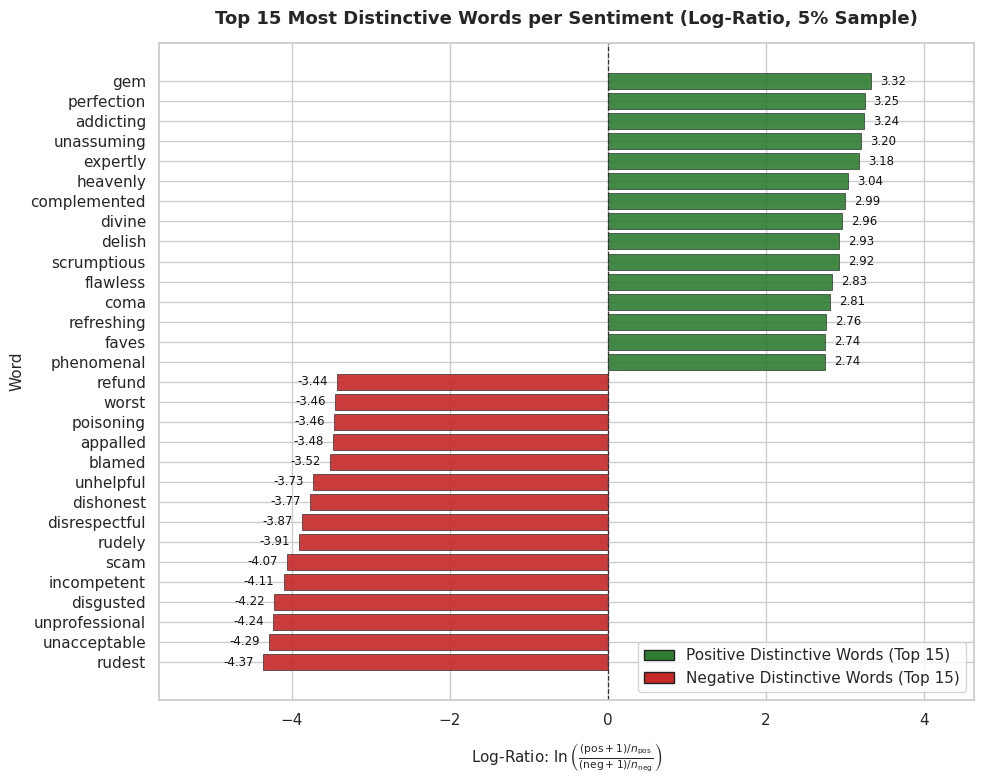

Chart verified: figures/04_top_words.png (364,983 bytes, shape=(2341, 2950, 4))


In [14]:
from matplotlib.patches import Patch

# Convert ONLY the top 15 positive and top 15 negative distinctive words (30 rows total) to Pandas.
try:
    top15_pos_pd = (
        ratio
        .orderBy(col("log_ratio").desc(), col("word").asc())
        .select("word", "neg", "pos", "log_ratio")
        .limit(15)
        .toPandas()
    )
    top15_pos_pd["sentiment"] = "Positive"

    top15_neg_pd = (
        ratio
        .orderBy(col("log_ratio").asc(), col("word").asc())
        .select("word", "neg", "pos", "log_ratio")
        .limit(15)
        .toPandas()
    )
    top15_neg_pd["sentiment"] = "Negative"
finally:
    pivot.unpersist(blocking=False)
    word_counts.unpersist(blocking=False)

assert len(top15_pos_pd) <= 15 and len(top15_neg_pd) <= 15
plot_df = pd.concat([top15_neg_pd, top15_pos_pd], ignore_index=True)
plot_df = plot_df.drop_duplicates(subset=["word"]).sort_values("log_ratio", ascending=True)
assert len(plot_df) <= 30, f"Expected at most 30 rows in plot_df, got {len(plot_df)}"

# Horizontal bar chart comparing top 15 positive vs top 15 negative distinctive words
fig, ax = plt.subplots(figsize=(10, 8))
color_map = {"Negative": "#C62828", "Positive": "#2E7D32"}
bar_colors = plot_df["sentiment"].map(color_map).tolist()

bars = ax.barh(
    plot_df["word"],
    plot_df["log_ratio"],
    color=bar_colors,
    edgecolor="#222222",
    linewidth=0.5,
    alpha=0.9
)

ax.axvline(0, color="#333333", linestyle="--", linewidth=0.9)
ax.set_title(
    "Top 15 Most Distinctive Words per Sentiment (Log-Ratio, 5% Sample)",
    fontsize=13,
    fontweight="bold",
    pad=14
)
ax.set_xlabel(
    r"Log-Ratio: $\ln\left(\frac{(\mathrm{pos}+1)/n_{\mathrm{pos}}}{(\mathrm{neg}+1)/n_{\mathrm{neg}}}\right)$",
    fontsize=11,
    labelpad=10
)
ax.set_ylabel("Word", fontsize=11)

# Annotate each bar with its log-ratio value
x_span = max(plot_df["log_ratio"].max() - plot_df["log_ratio"].min(), 1.0)
text_pad = 0.015 * x_span
for bar in bars:
    val = bar.get_width()
    ha = "left" if val >= 0 else "right"
    offset = text_pad if val >= 0 else -text_pad
    ax.text(
        val + offset,
        bar.get_y() + bar.get_height() / 2.0,
        f"{val:.2f}",
        va="center",
        ha=ha,
        fontsize=8.5,
        color="#111111"
    )

# Legend for visual distinction between positive and negative words
legend_handles = [
    Patch(facecolor="#2E7D32", edgecolor="#222222", label="Positive Distinctive Words (Top 15)"),
    Patch(facecolor="#C62828", edgecolor="#222222", label="Negative Distinctive Words (Top 15)"),
]
ax.legend(handles=legend_handles, loc="lower right", frameon=True)

xmin, xmax = ax.get_xlim()
ax.set_xlim(xmin - 0.12 * x_span, xmax + 0.12 * x_span)
plt.tight_layout()

os.makedirs("figures", exist_ok=True)
fig_path = "figures/04_top_words.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

# Verify saved figure exists, is non-empty, and has a valid PNG signature + decodable pixels
assert os.path.isfile(fig_path), f"Chart file not found: {fig_path}"
file_size = os.path.getsize(fig_path)
assert file_size > 0, f"Chart file is empty: {fig_path}"
with open(fig_path, "rb") as _f:
    assert _f.read(8) == b"\x89PNG\r\n\x1a\n", "Saved file is not a valid PNG image!"
_img = plt.imread(fig_path)
assert _img.ndim == 3 and _img.shape[0] > 100 and _img.shape[1] > 100, f"Unexpected image shape: {_img.shape}"
print(f"Chart verified: {fig_path} ({file_size:,} bytes, shape={_img.shape})")


**Interpretation:**

The verified actual Yelp 5% sample contains 314,338 reviews (234,283 positive and 80,055 negative), with an average of 54.19 filtered tokens per review. The log-ratio chart separates words disproportionately associated with positive and negative sentiment, and the verified synthetic and actual-data checks confirm that the 30-word visualization is valid.


In [15]:
# ==============================================================================
# MANDATORY TEST SUITE B — Actual Yelp Dataset End-to-End Verification (Colab)
# ==============================================================================
# Run this cell in Google Colab after executing Cells 0–25 against
# /content/drive/MyDrive/yelp_project/reviews_clean.parquet.

# 1. Verify non-empty sample and presence of both sentiment labels (0 and 1)
_label_counts = {
    row["label"]: row["count"]
    for row in sample_tok.groupBy("label").count().collect()
}
assert sum(_label_counts.values()) > 0, "Sample is empty!"
assert 0 in _label_counts and _label_counts[0] > 0, "Negative class (label=0) missing from sample!"
assert 1 in _label_counts and _label_counts[1] > 0, "Positive class (label=1) missing from sample!"

# 2. Verify valid filtered token arrays on sample_tok
_tok_stats = sample_tok.agg(
    fsum(when(col("filtered").isNull(), 1).otherwise(0)).alias("null_arrays"),
    avg(size(col("filtered"))).alias("avg_filtered_len"),
).first()
assert _tok_stats["null_arrays"] == 0, f"Found {_tok_stats['null_arrays']} null filtered arrays!"
assert _tok_stats["avg_filtered_len"] is not None and _tok_stats["avg_filtered_len"] > 0

# 3. Verify non-empty Top 20 results for both sentiments
_n_top20_pos = top20_pos.limit(20).count()
_n_top20_neg = top20_neg.limit(20).count()
assert _n_top20_pos == 20, f"Expected 20 positive top words, got {_n_top20_pos}"
assert _n_top20_neg == 20, f"Expected 20 negative top words, got {_n_top20_neg}"

# 4. Verify distinctive-word Pandas slices and log-ratio directionality
assert len(top15_pos_pd) == 15, f"Expected 15 positive distinctive words, got {len(top15_pos_pd)}"
assert len(top15_neg_pd) == 15, f"Expected 15 negative distinctive words, got {len(top15_neg_pd)}"
assert top15_pos_pd["log_ratio"].isna().sum() == 0
assert top15_neg_pd["log_ratio"].isna().sum() == 0
assert float(top15_pos_pd["log_ratio"].iloc[0]) > 0, "Top positive distinctive word should have log_ratio > 0"
assert float(top15_neg_pd["log_ratio"].iloc[0]) < 0, "Top negative distinctive word should have log_ratio < 0"

# 5. Verify saved chart file
assert os.path.isfile("figures/04_top_words.png") and os.path.getsize("figures/04_top_words.png") > 0

print("TEST SUITE B PASSED: All actual Yelp dataset verifications succeeded.")
print(f"Sample rows: {sum(_label_counts.values()):,} (Neg: {_label_counts[0]:,}, Pos: {_label_counts[1]:,})")
print(f"Avg filtered tokens/review: {_tok_stats['avg_filtered_len']:.2f}")
print("Top 5 positive distinctive words:", list(zip(top15_pos_pd["word"].head(5), top15_pos_pd["log_ratio"].round(3).head(5))))
print("Top 5 negative distinctive words:", list(zip(top15_neg_pd["word"].head(5), top15_neg_pd["log_ratio"].round(3).head(5))))


TEST SUITE B PASSED: All actual Yelp dataset verifications succeeded.
Sample rows: 314,338 (Neg: 80,055, Pos: 234,283)
Avg filtered tokens/review: 54.19
Top 5 positive distinctive words: [('gem', 3.323), ('perfection', 3.246), ('addicting', 3.241), ('unassuming', 3.201), ('expertly', 3.181)]
Top 5 negative distinctive words: [('rudest', -4.373), ('unacceptable', -4.293), ('unprofessional', -4.239), ('disgusted', -4.222), ('incompetent', -4.108)]
